In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("tips.csv")

X = df[["total_bill"]]
y = df["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("X_train:", len(X_train))
print("X_test:", len(X_test))
print("y_train:", len(y_train))
print("y_test:", len(y_test))

X_train: 170
X_test: 74
y_train: 170
y_test: 74


In [2]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.10889370921420226
Intercept: 0.8769576391532707


In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


I think it is important to keep 30% of the data for testing. The model does not see this data during training. This way, we can check if it works well with new data.

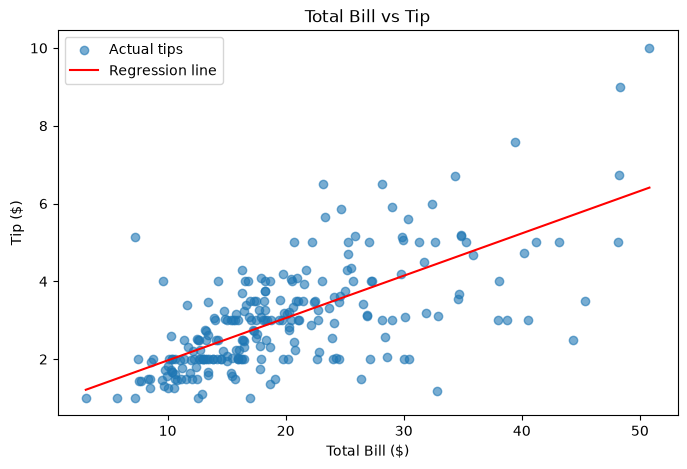

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(X["total_bill"], y, alpha=0.6, label="Actual tips")

X_sorted = X.sort_values("total_bill")
y_pred = model.predict(X_sorted)

plt.plot(X_sorted["total_bill"], y_pred, color="red", label="Regression line")

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.title("Total Bill vs Tip")
plt.legend()
plt.show()

When the total bill goes up by $1, the tip also goes up by about $0.11.

In [5]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

print("Total flowers:", len(X_iris))
print("Training:", len(X_train_i))
print("Testing:", len(X_test_i))

Total flowers: 150
Training: 105
Testing: 45


In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_i, y_train_i)

print("kNN Test Accuracy:", knn.score(X_test_i, y_test_i))

kNN Test Accuracy: 1.0


Decision Tree Test Accuracy: 1.0


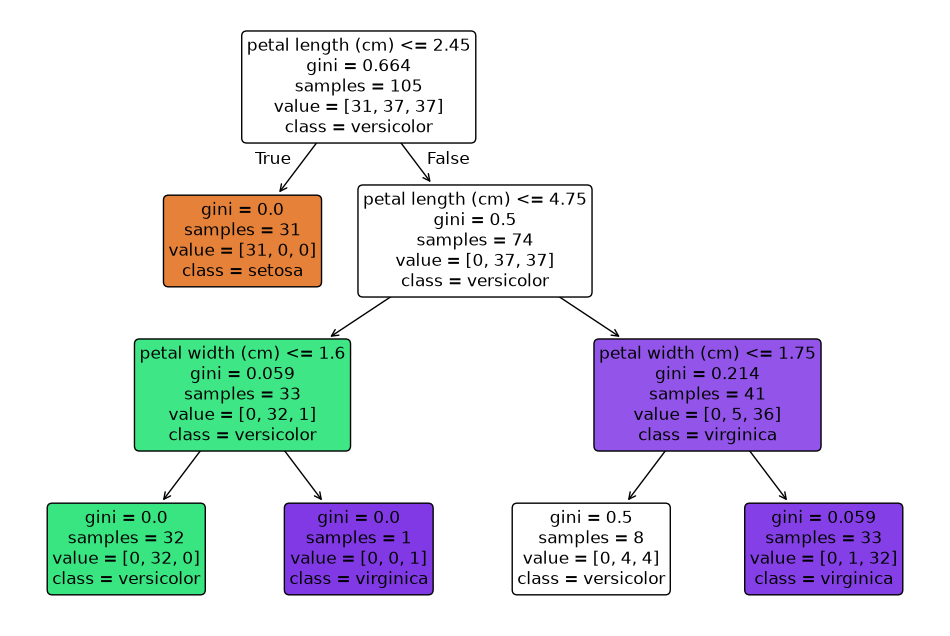

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train_i, y_train_i)

print("Decision Tree Test Accuracy:", tree.score(X_test_i, y_test_i))

plt.figure(figsize=(12, 8))
plot_tree(
    tree,
    feature_names=X_iris.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.show()

The tree first looks at the flower's petal length. If it is 2.45 cm or less, the flower is setosa. If it is longer, the tree checks other measurements.

In [8]:
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train_i, y_train_i)

results = pd.DataFrame({
    "Model": ["Shallow Tree", "Unlimited Tree"],
    "Train Score": [
        tree.score(X_train_i, y_train_i),
        full_tree.score(X_train_i, y_train_i)
    ],
    "Test Score": [
        tree.score(X_test_i, y_test_i),
        full_tree.score(X_test_i, y_test_i)
    ]
})

print(results)

            Model  Train Score  Test Score
0    Shallow Tree     0.952381         1.0
1  Unlimited Tree     1.000000         1.0


I see that the unlimited tree gets 100% on the training data. The smaller tree gets about 95%. Both trees have the same test score of 100%. I think the smaller tree is a good choice because it is simpler.

In [9]:
import pandas as pd

new_flower = pd.DataFrame(
    [[5.2, 3.1, 1.6, 0.4]],
    columns=X_iris.columns
)

prediction = knn.predict(new_flower)

print("Flower measurements:")
print(new_flower)
print("Predicted species:", iris.target_names[prediction[0]])

Flower measurements:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.2               3.1                1.6               0.4
Predicted species: setosa


In this lab, I used models to predict flower types. My new flower was predicted as setosa. I would choose the smaller decision tree because it is easy to understand. It got 100% accuracy on the test data. But I think the model could make mistakes with flowers that have unusual sizes. If we used a model like this for people, it could be unfair if the training data did not include different groups of people.